# NB3. Integracion solar del caso continuo

Este cuaderno continua el caso continuo de NB1 y NB2. Construye la escalera solar sobre la Gran Curva Compuesta, dimensiona el campo contra el EPW empaquetado, calcula la cobertura anual, audita las dos identidades de Primera Ley de la canibalizacion y ejecuta los dieciseis pasos de la subseccion 10.3.

La proyeccion horaria continua de SAM si se calcula aqui. El cuaderno ejecuta los dieciseis pasos de la subseccion 10.3, incluida la carga del archivo continuo `c53_results_continuous.csv`, su resumen anual y la re-verificacion de esa proyeccion contra el archivo nativo.

Cada magnitud impresa es un campo de un objeto devuelto, una clave de un diccionario o un valor de fila del marco cargado. Ninguna celda deriva cifras por diferencias, acumulacion ni rebanado de arreglos.

In [4]:
# Public wheel asset of pre-release v0.2.1, verified by real download: 705792 bytes,
# SHA-256 0861A3AF5E2A5AED69DE236596FD42675B3240ED0AAB9DB18252B84B05CBCA9A.
WHEEL_URL = "https://github.com/iwolde/ship-toolkit-releases/releases/download/v0.2.1/ship_toolkit-0.2.1-py3-none-any.whl"

_REQUIRED = "0.2.1"

import importlib.metadata
import importlib.util
import subprocess
import sys

try:
    _version = importlib.metadata.version("ship-toolkit")
except importlib.metadata.PackageNotFoundError:
    _version = None

if importlib.util.find_spec("ship_toolkit") is None or (
    _version is not None and _version != _REQUIRED
):
    if not WHEEL_URL:
        raise RuntimeError("WHEEL_URL is empty: the wheel has not been published yet.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", WHEEL_URL], check=True)
    try:
        _version = importlib.metadata.version("ship-toolkit")
    except importlib.metadata.PackageNotFoundError:
        _version = None

if _version is None:
    import ship_toolkit
    _version = getattr(ship_toolkit, "__version__", "sin version")

print("ship-toolkit", _version)

ship-toolkit 0.2.1


## Como se ejecuta este cuaderno

En Colab la celda de preparacion instala el paquete desde el wheel de la pre-release cuando `WHEEL_URL` tiene valor.

Los datos llegan por `data_path` desde el paquete instalado. No se sube ningun archivo a mano y no se lee de Google Drive.

En ejecucion local desde el repositorio la celda de preparacion no instala nada.

In [6]:
from pathlib import Path

from ship_toolkit import (
    apply_style,
    data_path,
    load_sam_continuous_csv,
    load_streams,
    plot_cannibalization,
    plot_solar_placement,
    run_pinch,
    solar_staircase,
)
from ship_toolkit.sam import (
    cannibalization_report,
    summarize_sam_continuous,
    verify_sam_projection,
)
from ship_toolkit.solar import (
    PARABOLIC_TROUGH_DSG,
    energy_for_area,
    field_area_for_energy,
    load_tmy,
    load_tmy_sin_ruta,
    load_tmy_synthetic,
    solar_coverage,
)

apply_style()
PATH_EPW = data_path("antofagasta_tmy.epw")

## El proceso y sus metas

El caso continuo es un conjunto de corrientes calientes y frias que opera sin interrupcion. Se resuelve con una aproximacion minima de 10.0 K y un paso de continuacion de 5.0 K, que son los valores usados en NB1 y NB2 y que se mantienen aqui para que las metas sean comparables entre cuadernos.

Las metas de servicio son el punto de partida de la integracion solar. El servicio caliente minimo es lo que una fuente solar puede desplazar; el servicio frio minimo y la recuperacion interna son el resto del sistema. La escalera solar mide cuanto de ese servicio caliente desplaza una fuente situada a cada nivel termico.

In [8]:
streams = load_streams(data_path("c53_continuous_streams.csv"))
result = run_pinch(streams, dT_min=10.0, dt_cont_K=5.0)

In [9]:
print(f"Qh_min  {result.Qh_min_kW:.1f} kW")
print(f"Qc_min  {result.Qc_min_kW:.1f} kW")
print(f"Qr      {result.Qr_kW:.1f} kW")
print(f"Pliegue en coordenadas corridas  {result.T_pinch_shifted_C:.1f} C")
print(f"Pliegue, lado caliente           {result.T_pinch_hot_C:.1f} C")
print(f"Pliegue, lado frio               {result.T_pinch_cold_C:.1f} C")

Qh_min  215.0 kW
Qc_min  32.0 kW
Qr      1328.0 kW
Pliegue en coordenadas corridas  122.0 C
Pliegue, lado caliente           127.0 C
Pliegue, lado frio               117.0 C


## La base meteorologica

El dimensionamiento del campo necesita una base horaria. La libreria empaqueta un archivo EPW de Antofagasta y expone tres rutas de carga sobre las mismas dieciocho claves: la ruta por defecto, que toma el archivo empaquetado; la ruta por argumento explicito, que recibe el archivo resuelto con la funcion de datos del paquete; y la ruta sin argumento, que devuelve exactamente la carga por defecto.

La cuarta ruta es el generador sintetico determinista, expuesto como funcion publica para pruebas y para docencia. Su perfil no es un archivo medido: su procedencia queda declarada en el campo de formato y en la ruta del diccionario que devuelve.

El diccionario devuelto porta cuatro magnitudes medidas sobre el archivo cargado: la suma horaria de la irradiancia directa normal convertida a energia anual por metro cuadrado, el maximo horario de esa misma serie, y el minimo y el maximo de la hora UTC. Se imprimen tal como las devuelve la libreria, sin normalizacion y sin recorte.

El cociente entre la irradiancia en el plano de apertura y la irradiancia global horizontal no es una clave de ese diccionario. Depende del plano inclinado y del albedo, de modo que es un diagnostico de la transposicion y no una propiedad del archivo. Sobre un plano inclinado a la latitud del sitio y con albedo 0.20 ese cociente vale 0.8155, y se declara aqui como diagnostico y no como magnitud almacenada.

## Procedencia del archivo meteorologico

El archivo empaquetado `antofagasta_tmy.epw` es un anio meteorologico tipico de PVGIS version 5.2, generado para el sitio de latitud -23.65 y longitud -70.40, con salida en formato EPW.

El repositorio no documenta el endpoint ni los parametros de descarga que produjeron ese archivo, de modo que la procedencia se declara aqui solo por version, sitio y formato.

El campo `year_provenance` del diccionario cargado confirma ese limite: el archivo no declara el anio de procedencia de cada hora.


In [11]:
tmy = load_tmy()
tmy_epw = load_tmy(PATH_EPW)
tmy_sin_ruta = load_tmy_sin_ruta()
tmy_sintetico = load_tmy_synthetic()

In [12]:
print(f"Sitio meteorologico:  {tmy['site']['name']}")
print(f"Archivo aplicado:     {Path(tmy['path']).name}")
print(f"Formato:              {tmy['format']}")
print(f"n_hours:              {tmy['n_hours']}")
print(f"Periodo declarado:    {tmy['data_period_label']}")
print(f"Procedencia del anio: {tmy['year_provenance']}")
print(f"DNI anual:            {tmy['dni_annual_kWh_per_m2']:.2f} kWh/m2")
print(f"DNI maximo horario:   {tmy['dni_peak_W_per_m2']:.2f} W/m2")
print(f"Hora UTC minima:      {tmy['hour_utc_min_h']:.1f} h")
print(f"Hora UTC maxima:      {tmy['hour_utc_max_h']:.1f} h")
print(f"Ruta con argumento:   formato {tmy_epw['format']}, n_hours {tmy_epw['n_hours']}")
print(f"Ruta sin argumento:   formato {tmy_sin_ruta['format']}, n_hours {tmy_sin_ruta['n_hours']}")
print(f"Sintetico:            formato {tmy_sintetico['format']}, n_hours {tmy_sintetico['n_hours']}")

Sitio meteorologico:  Antofagasta
Archivo aplicado:     antofagasta_tmy.epw
Formato:              epw
n_hours:              8760
Periodo declarado:    1/1 to 12/31
Procedencia del anio: not declared by file
DNI anual:            2748.17 kWh/m2
DNI maximo horario:   1144.04 W/m2
Hora UTC minima:      5.0 h
Hora UTC maxima:      28.0 h
Ruta con argumento:   formato epw, n_hours 8760
Ruta sin argumento:   formato epw, n_hours 8760
Sintetico:            formato deterministic synthetic, n_hours 8760


## La escalera solar y la regla de seleccion

La escalera se construye sobre un conjunto de niveles termicos. En cada nivel, el aporte absorbido es el flujo acumulado desde el pliegue hasta el nivel menos el paso de continuacion, y un nivel igual o superior al tope de la compuesta caliente satura en el servicio caliente minimo en vez de caer a cero.

El nivel declarado se obtiene por la regla del contrato: el nivel mas bajo del conjunto que satura el servicio caliente dentro de 1e-6 kW. Si ningun nivel del conjunto satura, se declara el mas alto y la cobertura parcial se imprime como premisa y nunca como resultado. El objeto devuelto no expone un campo de nivel elegido, de modo que la seleccion es una aplicacion de la regla en este cuaderno y no una magnitud almacenada por la libreria.

In [14]:
staircase = solar_staircase(streams, result, dt_cont_K=5.0)

In [15]:
for step in staircase.steps:
    print(
        f"Nivel {step.level_C:.1f} C"
        f"  absorbido {step.absorbed_kW:.1f} kW"
        f"  fraccion {step.fraction_frac:.4f}"
        f"  margen {step.pinch_margin_K:+.1f} K"
    )
print(f"saturation_level_C = {staircase.saturation_level_C:.1f} C")
print(f"Nivel declarado por la regla del contrato: {staircase.saturation_level_C:.1f} C")

Nivel 120.0 C  absorbido 0.0 kW  fraccion 0.0000  margen -7.0 K
Nivel 140.0 C  absorbido 91.0 kW  fraccion 0.4233  margen +13.0 K
Nivel 160.0 C  absorbido 167.0 kW  fraccion 0.7767  margen +33.0 K
Nivel 180.0 C  absorbido 215.0 kW  fraccion 1.0000  margen +53.0 K
Nivel 250.0 C  absorbido 215.0 kW  fraccion 1.0000  margen +123.0 K
saturation_level_C = 180.0 C
Nivel declarado por la regla del contrato: 180.0 C


## Dimensionamiento del campo y cobertura anual

El dimensionamiento del campo devuelve un area de apertura en metros cuadrados para una energia anual objetivo, y la operacion inversa devuelve la energia anual para un area fijada. Las dos funciones comparten el rendimiento especifico anual por metro cuadrado, de modo que la vuelta entre las dos reproduce la energia de partida.

La superficie de la red de intercambio no es una magnitud de este cuaderno: se mide en NB5. La cobertura se presenta como tabla con su numerador y su denominador, no como figura. El reporte de cobertura porta la fraccion, la energia solar util y la demanda anual, y no porta tolerancia ni residuo, de modo que este cuaderno no imprime un cierre de cobertura.

In [17]:
area_calculada_m2 = field_area_for_energy(energy_solar_kWh=500000.0, weather_path=PATH_EPW, collector=PARABOLIC_TROUGH_DSG, t_mean_C=110.0)
energia_entregada_kWh = energy_for_area(field_area_m2=1200.0, weather_path=PATH_EPW, collector=PARABOLIC_TROUGH_DSG, t_mean_C=110.0)
report_cov = solar_coverage(useful_solar_kWh=300000.0, annual_demand_kWh=500000.0)
report_cov_sobre = solar_coverage(useful_solar_kWh=750000.0, annual_demand_kWh=500000.0)

In [18]:
print("Dimensionamiento del campo")
print(f"  Area para 500000 kWh:   {area_calculada_m2:.4f} m2")
print(f"  Energia para 1200 m2:   {energia_entregada_kWh:.4f} kWh")
print("Cobertura anual")
print(f"  base:     {report_cov.useful_solar_kWh:.1f} / {report_cov.annual_demand_kWh:.1f} = {report_cov.coverage_frac:.4f}")
print(f"  sobreoferta: {report_cov_sobre.useful_solar_kWh:.1f} / {report_cov_sobre.annual_demand_kWh:.1f} = {report_cov_sobre.coverage_frac:.4f}")
print("La cobertura mayor que uno es sobreoferta y no se recorta.")

Dimensionamiento del campo
  Area para 500000 kWh:   310.0830 m2
  Energia para 1200 m2:   1934965.6126 kWh
Cobertura anual
  base:     300000.0 / 500000.0 = 0.6000
  sobreoferta: 750000.0 / 500000.0 = 1.5000
La cobertura mayor que uno es sobreoferta y no se recorta.


## Canibalizacion: las dos identidades

La auditoria cierra dos identidades independientes sobre el mismo horizonte. La primera se escribe en la frontera de salida del campo solar:

```text
oferta_kWh = directa_kWh + cargada_kWh + canibalizada_kWh + recortada_kWh
```

La segunda se escribe en el volumen de control del estanque de almacenamiento:

```text
cargada_kWh = descarga_util_kWh + perdidas_TES_kWh + remanente_final_kWh
```

La energia canibalizada conserva el signo libre: puede resultar negativa cuando la adicion solar genera sinergia con la recuperacion interna, y no se recorta a cero en ningun caso. La fraccion de canibalizacion se calcula sobre la oferta, que es el denominador de la primera identidad. Cada identidad tiene su propio residuo de potencia media en kW y su propio indicador booleano de cierre, y el constructor aplica una tolerancia de 1e-6 kW a los dos residuos. El cuaderno imprime los dos residuos y los tres booleanos tal como los devuelve el objeto.

In [20]:
report_canib = cannibalization_report(oferta_kWh=500000.0, directa_kWh=300000.0, cargada_kWh=150000.0, canibalizada_kWh=20000.0, recortada_kWh=30000.0, descarga_util_kWh=140000.0, perdidas_TES_kWh=8000.0, remanente_final_kWh=2000.0)
report_canib_neg = cannibalization_report(oferta_kWh=500000.0, directa_kWh=370000.0, cargada_kWh=150000.0, canibalizada_kWh=-50000.0, recortada_kWh=30000.0, descarga_util_kWh=140000.0, perdidas_TES_kWh=8000.0, remanente_final_kWh=2000.0)

In [21]:
print("Identidad 1, frontera de salida del campo")
print(f"  {report_canib.oferta_kWh:.1f} = {report_canib.directa_kWh:.1f} + {report_canib.cargada_kWh:.1f} + {report_canib.canibalizada_kWh:.1f} + {report_canib.recortada_kWh:.1f} kWh")
print(f"  fraccion de canibalizacion: {report_canib.canibalizada_kWh:.1f} / {report_canib.oferta_kWh:.1f} = {report_canib.canibalizacion_frac:.4f}")
print(f"  residual_1_kW = {report_canib.residual_1_kW:.6f} kW   closes_1 = {report_canib.closes_1}")
print("Identidad 2, estanque de almacenamiento")
print(f"  {report_canib.cargada_kWh:.1f} = {report_canib.descarga_util_kWh:.1f} + {report_canib.perdidas_TES_kWh:.1f} + {report_canib.remanente_final_kWh:.1f} kWh")
print(f"  residual_2_kW = {report_canib.residual_2_kW:.6f} kW   closes_2 = {report_canib.closes_2}   all_closed = {report_canib.all_closed}")
print("Escenario con canibalizacion negativa, sin recorte")
print(f"  canibalizada_kWh = {report_canib_neg.canibalizada_kWh:.1f} kWh")
print(f"  fraccion de canibalizacion: {report_canib_neg.canibalizada_kWh:.1f} / {report_canib_neg.oferta_kWh:.1f} = {report_canib_neg.canibalizacion_frac:.4f}")
print(f"  residual_1_kW = {report_canib_neg.residual_1_kW:.6f} kW   closes_1 = {report_canib_neg.closes_1}")

Identidad 1, frontera de salida del campo
  500000.0 = 300000.0 + 150000.0 + 20000.0 + 30000.0 kWh
  fraccion de canibalizacion: 20000.0 / 500000.0 = 0.0400
  residual_1_kW = 0.000000 kW   closes_1 = True
Identidad 2, estanque de almacenamiento
  150000.0 = 140000.0 + 8000.0 + 2000.0 kWh
  residual_2_kW = 0.000000 kW   closes_2 = True   all_closed = True
Escenario con canibalizacion negativa, sin recorte
  canibalizada_kWh = -50000.0 kWh
  fraccion de canibalizacion: -50000.0 / 500000.0 = -0.1000
  residual_1_kW = 0.000000 kW   closes_1 = True


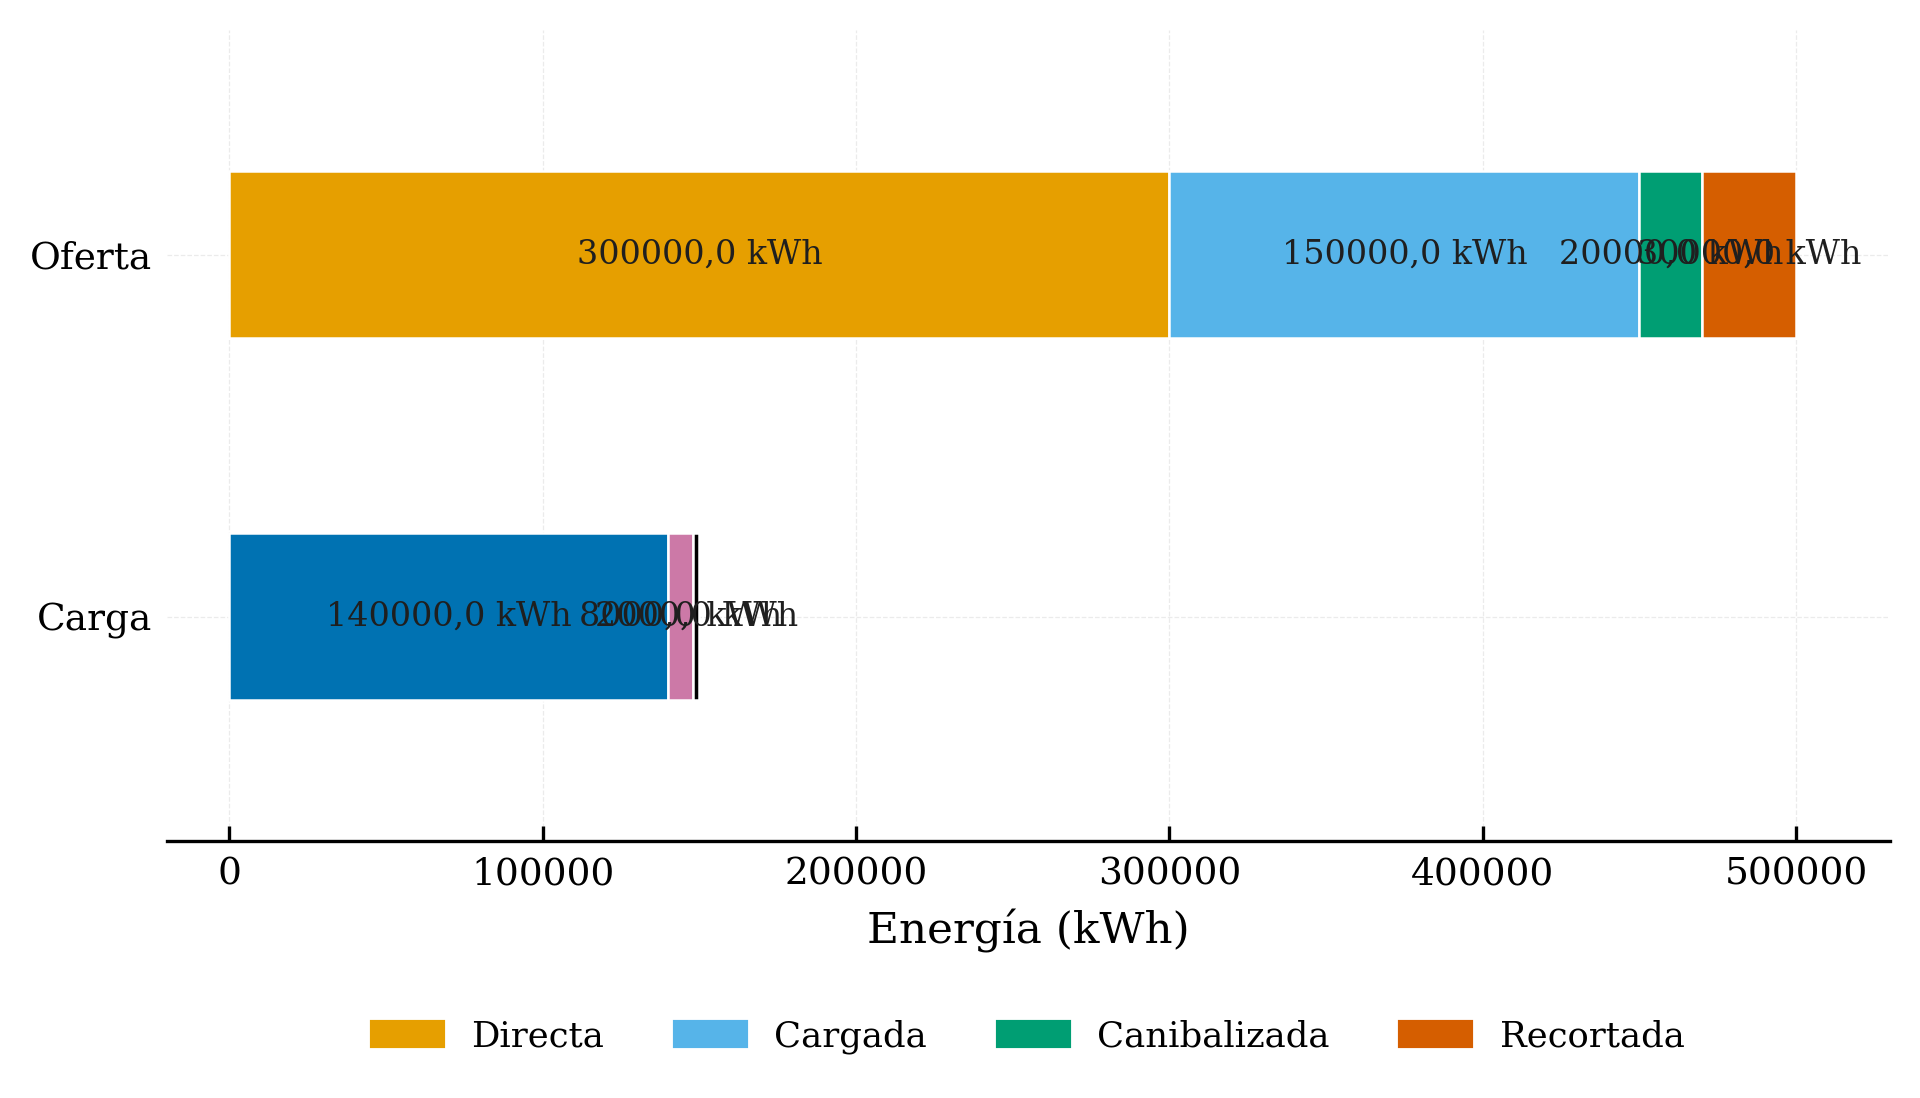

In [22]:
fig_canib = plot_cannibalization(report_canib)

## Colocacion del nivel solar sobre la Gran Curva Compuesta

La figura siguiente situa el nivel declarado por la regla sobre la Gran Curva Compuesta y muestra el peldano que satura el servicio caliente. La escalera no se vuelve a dibujar aqui: su productor y su lugar es NB2, y repetirla desviaria la lectura de esta figura hacia el detalle por nivel en vez de la colocacion sobre la curva.

El eje vertical es temperatura y el eje horizontal es carga termica neta. Un nivel que queda por debajo del pliegue caliente no desplaza servicio, y su margen de pliegue lo declara con signo negativo en la tabla de la escalera.

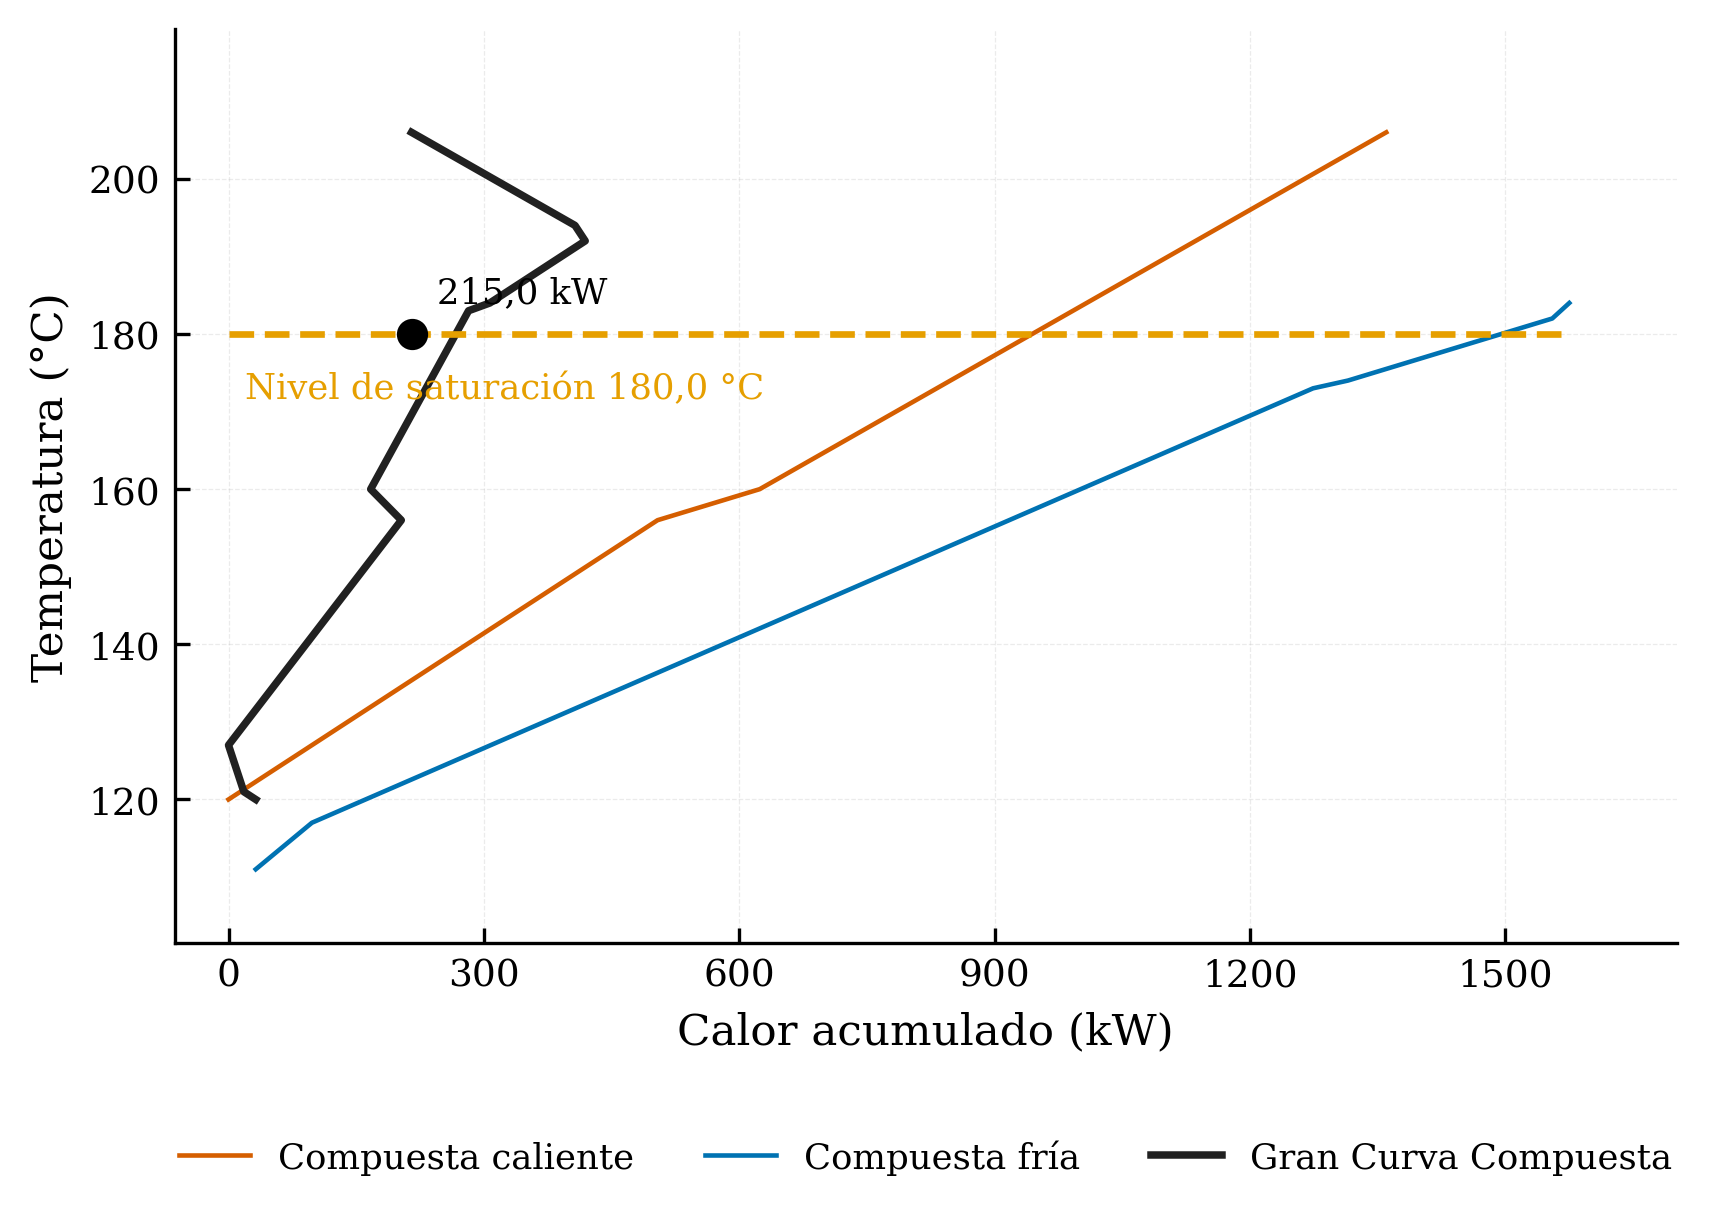

In [24]:
fig_placement = plot_solar_placement(result, staircase)

## La proyeccion horaria continua de SAM

El archivo `c53_results_continuous.csv` es la proyeccion horaria continua de SAM del caso continuo: 8760 filas horarias y la cabecera nativa del exportador. El cargador lo lee, valida la cabecera y devuelve un marco con los nombres del paquete.

Los pasos 4, 12 y 13 de la subseccion 10.3 corren aqui. La carga devuelve el marco horario, el resumen anual devuelve cuatro magnitudes medidas y la re-verificacion vuelve a leer el archivo nativo y compara su energia anual contra la del marco cargado con una tolerancia declarada.

Las dos magnitudes por fila que se imprimen son la primera fila de la potencia entregada al sumidero y la primera fila de la irradiancia directa normal, de modo que la lista de cifras disponibles de la subseccion queda ejercitada tambien en su nivel horario.

In [26]:
sam_continuous = load_sam_continuous_csv(data_path("c53_results_continuous.csv"))
resumen_sam = summarize_sam_continuous(sam_continuous, energy_column="sink_kW")
auditoria_sam = verify_sam_projection(str(data_path("c53_results_continuous.csv")), sam_continuous)

In [27]:
print("Proyeccion horaria continua de SAM")
print(f"  energia anual:        {resumen_sam.annual_energy_kWh:.4f} kWh")
print(f"  potencia maxima:      {resumen_sam.peak_power_kW:.4f} kW")
print(f"  horas con entrega:    {resumen_sam.hours_delivering_h:.1f} h")
print(f"  horas nulas:          {resumen_sam.null_hours_h:.1f} h")
print("Re-verificacion de la proyeccion")
print(f"  residual de energia:  {auditoria_sam.residual_kWh:.6f} kWh")
print(f"  cierre:               {auditoria_sam.closes}")
print(f"  tolerancia:           {auditoria_sam.tolerance_kWh:.6e} kWh")
print("Primera fila del marco cargado")
print(f"  sink_kW:              {sam_continuous['sink_kW'].iloc[0]:.4f} kW")
print(f"  dni_W_m2:             {sam_continuous['dni_W_m2'].iloc[0]:.4f} W/m2")

Proyeccion horaria continua de SAM
  energia anual:        876222.5207 kWh
  potencia maxima:      215.1050 kW
  horas con entrega:    4419.0 h
  horas nulas:          4341.0 h
Re-verificacion de la proyeccion
  residual de energia:  0.000000 kWh
  cierre:               True
  tolerancia:           1.000000e-06 kWh
Primera fila del marco cargado
  sink_kW:              215.0020 kW
  dni_W_m2:             0.0000 W/m2


In [ ]:
# Supuesto declarado de este cuaderno: en el caso C53 la demanda termica vale 215 kW.
# En la Tarea 5 esta demanda debe venir del analisis Pinch del alumno y de las horas
# de operacion reales, no de un numero fijo.
DEMANDA_TERMICA_KW = result.Qh_min_kW

q_solar_util_kW = sam_continuous["sink_kW"].clip(upper=DEMANDA_TERMICA_KW)
energia_solar_util_kWh = q_solar_util_kW.sum()
demanda_anual_kWh = DEMANDA_TERMICA_KW * len(sam_continuous)
fraccion_horaria = q_solar_util_kW / DEMANDA_TERMICA_KW
fraccion_anual = energia_solar_util_kWh / demanda_anual_kWh

reporte_fraccion = solar_coverage(
    useful_solar_kWh=energia_solar_util_kWh, annual_demand_kWh=demanda_anual_kWh
)

print("Fraccion solar sobre la demanda declarada")
print(f"  demanda declarada:       {DEMANDA_TERMICA_KW:.1f} kW")
print(f"  energia solar util:      {energia_solar_util_kWh:.4f} kWh")
print(f"  demanda anual:           {demanda_anual_kWh:.4f} kWh")
print(f"  fraccion horaria minima: {fraccion_horaria.min():.6f}")
print(f"  fraccion horaria media:  {fraccion_horaria.mean():.6f}")
print(f"  fraccion horaria maxima: {fraccion_horaria.max():.6f}")
print(f"  fraccion anual:          {fraccion_anual:.6f}")
print(f"  coverage_frac reporte:   {reporte_fraccion.coverage_frac:.6f}")
print("La demanda es un supuesto declarado en esta celda.")
print("En la Tarea 5 debe venir del analisis Pinch y de las horas de operacion reales.")


## Que ensena este cuaderno

La escalera satura desde 180.0 C en este conjunto, con un inicio fisico de 169.6 C, y por encima de ese nivel no se desplaza servicio caliente adicional: los dos ultimos peldanos absorben lo mismo. El nivel declarado no es una constante fisica del proceso sino el primer nivel del conjunto suministrado que alcanza la meta.

El dimensionamiento del campo es un area en metros cuadrados, no un limite del diseno. La tabla de cobertura muestra que una cobertura mayor que uno es sobreoferta y que el reporte no la recorta. La auditoria de canibalizacion cierra las dos identidades y conserva el valor negativo de la energia canibalizada en lugar de forzarlo a cero.

La proyeccion horaria continua de SAM se carga y se resume sobre el mismo año de 8760 horas, y su re-verificacion contra el archivo nativo cierra con residuo nulo bajo la tolerancia declarada del objeto. La energia anual resumida es 876222.5207 kWh, la potencia maxima es 215.1050 kW y las horas con entrega son 4419.0 frente a 4341.0 horas nulas.